In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

project = Path.cwd()
if not (project / "data").is_dir():
    project = project.parent

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from src.feature_preparation import (
    make_features,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    ENGINEERED_FEATURES,
)

dev = pd.read_csv(
    project / "data/processed/development.csv",
    dtype={"ID": "string"},
    low_memory=False
)

X_original = make_features(dev, engineered=False)
X_engineered = make_features(dev, engineered=True)
y = dev["Rej_and_cut_Piece"].copy()

assert set(dev["cv_fold"].unique()) == set(range(5))
assert dev.groupby("ID")["cv_fold"].nunique().eq(1).all()

print("Original feature table:", X_original.shape)
print("Engineered feature table:", X_engineered.shape)

print("\nMissing values after feature preparation:")
display(X_engineered.isna().sum())

display(X_engineered.head())

Original feature table: (16139, 8)
Engineered feature table: (16139, 11)

Missing values after feature preparation:


Req_Finish_Fabrics      0
Fabric_Allowance        0
Shrink_allow            0
Req_grey_fabric         0
Req_beam_length(yds)    0
epi                     0
ppi                     0
Construction            0
epi_ppi_product         0
epi_ppi_ratio           0
planned_grey_extra      0
dtype: int64

,Req_Finish_Fabrics,Fabric_Allowance,Shrink_allow,Req_grey_fabric,Req_beam_length(yds),epi,ppi,Construction,epi_ppi_product,epi_ppi_ratio,planned_grey_extra
0,31300,6.0,12.5,33297.872340,34797.651100,110,80,40+40/2/40/110x80,8800,1.375000,1997.872340
1,10450,7.0,14.5,11236.559140,12017.350430,110,90,40x40/110x90,9900,1.222222,786.559140
2,900,11.5,12.5,1016.949153,1062.753843,110,80,40x40/110x80,8800,1.375000,116.949153
3,8000,8.0,14.0,8695.652174,9245.815159,130,80,40x40/130x80,10400,1.625000,695.652174
4,3500,8.1,9.1,3808.487486,3831.158751,140,70,50x50/140x70,9800,2.000000,308.487486


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor(engineered=False, scale_numeric=False):
    numeric_columns = NUMERIC_FEATURES.copy()

    if engineered:
        numeric_columns += ENGINEERED_FEATURES

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ])


print("Preprocessing definitions are ready.")

Preprocessing definitions are ready.


In [3]:
# Use fold 0 as validation for this preprocessing check
training_rows = dev["cv_fold"].ne(0)
validation_rows = dev["cv_fold"].eq(0)

preprocessor_check = build_preprocessor(
    engineered=True,
    scale_numeric=True
)

training_array = preprocessor_check.fit_transform(
    X_engineered.loc[training_rows]
)

validation_array = preprocessor_check.transform(
    X_engineered.loc[validation_rows]
)

assert np.isfinite(training_array).all()
assert np.isfinite(validation_array).all()
assert training_array.shape[1] == validation_array.shape[1]

print("Training array:", training_array.shape)
print("Validation array:", validation_array.shape)
print("Preprocessing check passed.")

Training array: (12911, 104)
Validation array: (3228, 104)
Preprocessing check passed.


In [4]:
from time import perf_counter
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

models = {
    "Median baseline": DummyRegressor(strategy="median"),

    "Ridge": Ridge(alpha=1.0),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        early_stopping=False,
        random_state=42,
    ),
}

print("Median baseline and five regression models are ready.")

Median baseline and five regression models are ready.


In [5]:
feature_versions = {
    "Original": (X_original, False),
    "Engineered": (X_engineered, True),
}

fold_results = []
prediction_records = []
completed = 0

for feature_name, (X, engineered) in feature_versions.items():
    for model_name, estimator in models.items():

        # The median baseline does not depend on feature engineering
        if model_name == "Median baseline" and engineered:
            continue

        for fold in range(5):
            train_positions = np.flatnonzero(
                dev["cv_fold"].to_numpy() != fold
            )
            validation_positions = np.flatnonzero(
                dev["cv_fold"].to_numpy() == fold
            )

            # A fresh pipeline is fitted separately within every fold
            pipeline = Pipeline([
                (
                    "preprocessing",
                    build_preprocessor(
                        engineered=engineered,
                        scale_numeric=(model_name == "Ridge"),
                    ),
                ),
                ("model", clone(estimator)),
            ])

            start = perf_counter()
            pipeline.fit(
                X.iloc[train_positions],
                y.iloc[train_positions],
            )
            fit_seconds = perf_counter() - start

            start = perf_counter()
            predictions = pipeline.predict(
                X.iloc[validation_positions]
            )
            predict_seconds = perf_counter() - start

            actual = y.iloc[validation_positions]

            mae = mean_absolute_error(actual, predictions)
            rmse = np.sqrt(
                mean_squared_error(actual, predictions)
            )
            r2 = r2_score(actual, predictions)

            fold_results.append({
                "Feature_set": feature_name,
                "Model": model_name,
                "Fold": fold,
                "MAE": mae,
                "RMSE": rmse,
                "R2": r2,
                "Fit_seconds": fit_seconds,
                "Predict_seconds": predict_seconds,
            })

            prediction_records.append(pd.DataFrame({
                "source_row": dev.iloc[
                    validation_positions
                ]["source_row"].to_numpy(),
                "ID": dev.iloc[
                    validation_positions
                ]["ID"].to_numpy(),
                "Feature_set": feature_name,
                "Model": model_name,
                "Fold": fold,
                "Actual": actual.to_numpy(),
                "Predicted": predictions,
            }))

            completed += 1
            print(
                f"{completed}/55 | {feature_name} | "
                f"{model_name} | Fold {fold + 1} | "
                f"MAE: {mae:.2f}",
                flush=True,
            )

print("Initial grouped cross-validation completed.")

1/55 | Original | Median baseline | Fold 1 | MAE: 102.50
2/55 | Original | Median baseline | Fold 2 | MAE: 146.43
3/55 | Original | Median baseline | Fold 3 | MAE: 100.08
4/55 | Original | Median baseline | Fold 4 | MAE: 82.07
5/55 | Original | Median baseline | Fold 5 | MAE: 72.51
6/55 | Original | Ridge | Fold 1 | MAE: 137.70
7/55 | Original | Ridge | Fold 2 | MAE: 163.72
8/55 | Original | Ridge | Fold 3 | MAE: 143.12
9/55 | Original | Ridge | Fold 4 | MAE: 130.02
10/55 | Original | Ridge | Fold 5 | MAE: 110.75
11/55 | Original | Decision Tree | Fold 1 | MAE: 151.09
12/55 | Original | Decision Tree | Fold 2 | MAE: 157.34
13/55 | Original | Decision Tree | Fold 3 | MAE: 149.48
14/55 | Original | Decision Tree | Fold 4 | MAE: 142.57
15/55 | Original | Decision Tree | Fold 5 | MAE: 120.71
16/55 | Original | Random Forest | Fold 1 | MAE: 146.48
17/55 | Original | Random Forest | Fold 2 | MAE: 160.36
18/55 | Original | Random Forest | Fold 3 | MAE: 149.86
19/55 | Original | Random Forest 

In [6]:
results = pd.DataFrame(fold_results)

comparison = (
    results.groupby(["Feature_set", "Model"])
    .agg(
        MAE=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2=("R2", "mean"),
        R2_std=("R2", "std"),
        Fit_seconds=("Fit_seconds", "mean"),
        Predict_seconds=("Predict_seconds", "mean"),
    )
    .reset_index()
    .sort_values("MAE")
)

display(comparison.round(4))

results.to_csv(
    project / "reports/initial_cv_fold_results.csv",
    index=False,
)

comparison.to_csv(
    project / "reports/initial_model_comparison.csv",
    index=False,
)

pd.concat(prediction_records, ignore_index=True).to_csv(
    project / "data/processed/initial_cv_predictions.csv",
    index=False,
)

print("Comparison, fold results, and validation predictions saved.")

,Feature_set,Model,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,Fit_seconds,Predict_seconds
8,Original,Median baseline,100.7195,28.4464,459.2165,208.6317,-0.0442,0.0172,0.0443,0.0090
6,Original,Extra Trees,131.1547,27.4183,517.4753,205.0834,-0.4552,0.6710,4.0540,0.0777
1,Engineered,Extra Trees,131.4489,28.6036,520.8120,206.3293,-0.4863,0.7340,3.8134,0.0720
4,Engineered,Ridge,137.0136,21.4187,446.6047,208.1738,0.0219,0.0256,0.0543,0.0088
10,Original,Ridge,137.0645,19.2989,447.3002,206.9741,0.0171,0.0281,0.0501,0.0094
9,Original,Random Forest,137.8975,22.0729,547.1117,183.6057,-0.6740,0.6945,2.3136,0.0911
3,Engineered,Random Forest,138.9891,24.4694,548.1720,188.1862,-0.6769,0.7207,2.2139,0.0703
0,Engineered,Decision Tree,143.4796,17.0526,637.7945,134.8560,-1.7488,2.0817,0.1286,0.0090
5,Original,Decision Tree,144.2383,14.1638,643.1127,125.4965,-1.8092,2.0715,0.1372,0.0111
2,Engineered,Histogram Gradient Boosting,154.2724,19.9405,532.0487,197.4168,-0.5109,0.3792,1.5347,0.0327


Comparison, fold results, and validation predictions saved.


In [7]:
import json
import platform
import sklearn

from time import perf_counter
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from joblib import parallel_config

# Reuse the exact saved grouped folds
cv_splits = []

for fold in range(5):
    train_positions = np.flatnonzero(
        dev["cv_fold"].to_numpy() != fold
    )
    validation_positions = np.flatnonzero(
        dev["cv_fold"].to_numpy() == fold
    )

    train_ids = set(dev.iloc[train_positions]["ID"])
    validation_ids = set(dev.iloc[validation_positions]["ID"])

    assert train_ids.isdisjoint(validation_ids)

    cv_splits.append((train_positions, validation_positions))

# Six sampled configurations per algorithm per feature version
N_ITER = 6

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

search_spaces = {
    "Ridge": {
        "model__alpha": np.logspace(-3, 6, 30).tolist(),
    },

    "Decision Tree": {
        "model__criterion": [
            "squared_error", "absolute_error"
        ],
        "model__max_depth": [3, 6, 12, None],
        "model__min_samples_leaf": [5, 20, 100, 300],
        "model__ccp_alpha": [0.0, 0.1, 1.0, 10.0],
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [4, 8, None],
        "model__min_samples_leaf": [5, 20, 100, 300],
        "model__max_features": [0.5, 1.0],
        "model__max_samples": [0.7, None],
    },

    "Extra Trees": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [4, 8, None],
        "model__min_samples_leaf": [5, 20, 100, 300],
        "model__max_features": [0.5, 1.0],
    },

    "Histogram Gradient Boosting": {
        "model__loss": [
            "squared_error", "absolute_error"
        ],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_iter": [100, 200, 300],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__l2_regularization": [0.0, 1.0, 10.0, 100.0],
    },
}

tuning_folder = project / "reports/tuning"
tuning_folder.mkdir(parents=True, exist_ok=True)

metadata = {
    "random_seed": 42,
    "candidates_per_model_per_feature_version": N_ITER,
    "folds": 5,
    "primary_metric": "MAE",
    "search_parallel_jobs": 2,
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "search_spaces": search_spaces,
}

(tuning_folder / "run_settings.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Tuning settings saved.")
print("Total parameter configurations:", 5 * 2 * N_ITER)
print("Total cross-validation fits:", 5 * 2 * N_ITER * 5)

Tuning settings saved.
Total parameter configurations: 60
Total cross-validation fits: 300


In [8]:
feature_versions = {
    "Original": (X_original, False),
    "Engineered": (X_engineered, True),
}

tuning_rows = []
best_parameter_records = []

for feature_name, (X, engineered) in feature_versions.items():
    for model_name, parameter_space in search_spaces.items():

        print(
            f"\nStarting: {feature_name} | {model_name}",
            flush=True,
        )

        estimator = clone(models[model_name])

        # Parallelize searches rather than forest trees simultaneously
        if "n_jobs" in estimator.get_params():
            estimator.set_params(n_jobs=1)

        pipeline = Pipeline([
            (
                "preprocessing",
                build_preprocessor(
                    engineered=engineered,
                    scale_numeric=(model_name == "Ridge"),
                ),
            ),
            ("model", estimator),
        ])

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=parameter_space,
            n_iter=N_ITER,
            scoring=scoring,
            cv=cv_splits,
            refit=False,
            random_state=42,
            n_jobs=2,
            pre_dispatch=2,
            verbose=2,
            error_score="raise",
            return_train_score=False,
        )

        start = perf_counter()

        with parallel_config(
            backend="loky",
            inner_max_num_threads=1,
        ):
            search.fit(X, y)

        search_seconds = perf_counter() - start

        trials = pd.DataFrame(search.cv_results_)

        # Negative MAE closest to zero is best
        best_index = trials["mean_test_MAE"].idxmax()
        best_trial = trials.loc[best_index]

        fold_mae = [
            -best_trial[f"split{i}_test_MAE"]
            for i in range(5)
        ]
        fold_rmse = [
            -best_trial[f"split{i}_test_RMSE"]
            for i in range(5)
        ]
        fold_r2 = [
            best_trial[f"split{i}_test_R2"]
            for i in range(5)
        ]

        tuning_rows.append({
            "Feature_set": feature_name,
            "Model": model_name,
            "MAE": np.mean(fold_mae),
            "MAE_std": np.std(fold_mae, ddof=1),
            "RMSE": np.mean(fold_rmse),
            "RMSE_std": np.std(fold_rmse, ddof=1),
            "R2": np.mean(fold_r2),
            "R2_std": np.std(fold_r2, ddof=1),
            "Mean_CV_fit_seconds": best_trial["mean_fit_time"],
            "Search_seconds": search_seconds,
        })

        best_parameter_records.append({
            "Feature_set": feature_name,
            "Model": model_name,
            "Parameters": search.cv_results_["params"][best_index],
        })

        file_label = (
            f"{feature_name}_{model_name}"
            .lower()
            .replace(" ", "_")
        )

        # Save a checkpoint after every completed search
        trials.to_csv(
            tuning_folder / f"{file_label}_trials.csv",
            index=False,
        )

        pd.DataFrame(tuning_rows).to_csv(
            tuning_folder / "tuned_model_comparison.csv",
            index=False,
        )

        (tuning_folder / "best_parameters.json").write_text(
            json.dumps(best_parameter_records, indent=2),
            encoding="utf-8",
        )

        print(
            f"Completed: {feature_name} | {model_name} | "
            f"Best CV MAE: {np.mean(fold_mae):.2f}",
            flush=True,
        )

print("\nAll ten tuning searches completed.")


Starting: Original | Ridge
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Original | Ridge | Best CV MAE: 136.86

Starting: Original | Decision Tree
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Original | Decision Tree | Best CV MAE: 98.36

Starting: Original | Random Forest
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Original | Random Forest | Best CV MAE: 127.16

Starting: Original | Extra Trees
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Original | Extra Trees | Best CV MAE: 124.84

Starting: Original | Histogram Gradient Boosting
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Original | Histogram Gradient Boosting | Best CV MAE: 97.03

Starting: Engineered | Ridge
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Completed: Engineered | Ridge | Best CV MAE: 135.66

Starting: Engineered | Decision Tree
Fitting 5 folds for each of 6 candidates, to

In [12]:
tuned_comparison = (
    pd.DataFrame(tuning_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Tuned configurations:")
display(tuned_comparison.round(4))

initial = pd.read_csv(
    project / "reports/initial_model_comparison.csv"
)

metric_columns = [
    "Feature_set", "Model",
    "MAE", "MAE_std",
    "RMSE", "RMSE_std",
    "R2", "R2_std",
]

all_candidates = pd.concat([
    initial[metric_columns].assign(Stage="Initial"),
    tuned_comparison[metric_columns].assign(Stage="Tuned"),
], ignore_index=True)

# Retain the lowest-CV-MAE candidate for each model family
best_per_model = (
    all_candidates
    .sort_values("MAE")
    .groupby("Model", sort=False)
    .head(1)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Best development-CV result per model, including baseline:")
display(best_per_model.round(4))

all_candidates.to_csv(
    tuning_folder / "initial_and_tuned_comparison.csv",
    index=False,
)

best_per_model.to_csv(
    tuning_folder / "best_per_model.csv",
    index=False,
)

Tuned configurations:


,Feature_set,Model,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,Mean_CV_fit_seconds,Search_seconds
0,Engineered,Histogram Gradient Boosting,96.4400,29.1489,454.6618,211.7132,-0.0153,0.0207,1.4953,33.2156
1,Original,Histogram Gradient Boosting,97.0253,29.1700,455.8075,211.0881,-0.0225,0.0196,1.3527,32.4763
2,Original,Decision Tree,98.3554,29.6027,455.2914,209.3866,-0.0226,0.0075,0.6499,12.1108
3,Engineered,Decision Tree,98.3949,30.0231,455.1119,209.7712,-0.0213,0.0105,0.6103,11.5354
4,Original,Extra Trees,124.8430,22.6435,460.3199,205.1263,-0.0597,0.1706,3.9513,112.0749
5,Engineered,Extra Trees,125.9446,22.8224,462.6795,205.5575,-0.0725,0.1849,4.4926,120.4257
6,Original,Random Forest,127.1612,23.1485,476.1166,214.5957,-0.1297,0.2211,2.3553,49.7727
7,Engineered,Random Forest,129.8054,23.8821,475.7348,216.3986,-0.1225,0.2013,2.5286,49.3784
8,Engineered,Ridge,135.6612,21.7828,445.2021,208.6782,0.0292,0.0189,0.0297,0.7049
9,Original,Ridge,136.8551,21.3301,446.3809,207.5954,0.0217,0.0151,0.0335,14.8161


Best development-CV result per model, including baseline:


,Feature_set,Model,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,Stage
0,Engineered,Histogram Gradient Boosting,96.4400,29.1489,454.6618,211.7132,-0.0153,0.0207,Tuned
1,Original,Decision Tree,98.3554,29.6027,455.2914,209.3866,-0.0226,0.0075,Tuned
2,Original,Median baseline,100.7195,28.4464,459.2165,208.6317,-0.0442,0.0172,Initial
3,Original,Extra Trees,124.8430,22.6435,460.3199,205.1263,-0.0597,0.1706,Tuned
4,Original,Random Forest,127.1612,23.1485,476.1166,214.5957,-0.1297,0.2211,Tuned
5,Engineered,Ridge,135.6612,21.7828,445.2021,208.6782,0.0292,0.0189,Tuned


In [13]:
import json
import joblib

from time import perf_counter
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer

from src.feature_preparation import (
    make_features,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)

# Select using development CV results only
ranking = pd.read_csv(
    tuning_folder / "best_per_model.csv"
).sort_values("MAE")

winner = ranking.iloc[0]

assert winner["Stage"] == "Tuned", (
    "The leading candidate is not a tuned model. Review selection."
)

selected_name = winner["Model"]
selected_features = winner["Feature_set"]
use_engineered = selected_features == "Engineered"

# Recover the exact settings that produced this result
parameter_records = json.loads(
    (tuning_folder / "best_parameters.json").read_text(
        encoding="utf-8"
    )
)

matching_settings = [
    record for record in parameter_records
    if record["Model"] == selected_name
    and record["Feature_set"] == selected_features
]

assert len(matching_settings) == 1
selected_parameters = matching_settings[0]["Parameters"]

# Include feature preparation inside the complete pipeline
selected_pipeline = Pipeline([
    (
        "features",
        FunctionTransformer(
            make_features,
            kw_args={"engineered": use_engineered},
            validate=False,
        ),
    ),
    (
        "preprocessing",
        build_preprocessor(
            engineered=use_engineered,
            scale_numeric=(selected_name == "Ridge"),
        ),
    ),
    ("model", clone(models[selected_name])),
])

selected_pipeline.set_params(**selected_parameters)

input_columns = NUMERIC_FEATURES + CATEGORICAL_FEATURES

selection_record = {
    "model": selected_name,
    "feature_version": selected_features,
    "parameters": selected_parameters,
    "selection_metric": "Mean grouped CV MAE",
    "development_cv_MAE": float(winner["MAE"]),
    "development_cv_RMSE": float(winner["RMSE"]),
    "development_cv_R2": float(winner["R2"]),
    "input_columns": input_columns,
    "target": "Rej_and_cut_Piece",
    "target_interpretation": "Recorded combined rejection-and-cut-piece amount",
    "test_evaluated": False,
}

# Record our decision before evaluating test data
selection_path = project / "reports/selected_model_config.json"
selection_path.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)

# Fit the chosen configuration on all development records
start = perf_counter()

selected_pipeline.fit(
    dev[input_columns],
    dev["Rej_and_cut_Piece"],
)

selection_record["development_fit_seconds"] = (
    perf_counter() - start
)

model_folder = project / "models"
model_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(
    selected_pipeline,
    model_folder / "weaveiq_selected_pipeline.joblib",
)

selection_path.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)

print("Selected model:", selected_name)
print("Feature version:", selected_features)
print("Best parameters:")
print(json.dumps(selected_parameters, indent=2))
print("Trained on development records:", len(dev))
print("Complete pipeline saved.")
print("Reserved test data has not been evaluated.")

Selected model: Histogram Gradient Boosting
Feature version: Engineered
Best parameters:
{
  "model__min_samples_leaf": 100,
  "model__max_leaf_nodes": 15,
  "model__max_iter": 200,
  "model__loss": "absolute_error",
  "model__learning_rate": 0.03,
  "model__l2_regularization": 1.0
}
Trained on development records: 16139
Complete pipeline saved.
Reserved test data has not been evaluated.


In [14]:
import json
import joblib
import numpy as np
import pandas as pd

from time import perf_counter
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Define the high-rejection threshold before inspecting test outcomes
high_threshold = float(
    dev["Rej_and_cut_Piece"].quantile(0.95)
)

selection_path = project / "reports/selected_model_config.json"

selection_record = json.loads(
    selection_path.read_text(encoding="utf-8")
)

selection_record["high_rejection_threshold"] = high_threshold
selection_record["high_rejection_rule"] = (
    "Target >= development target 95th percentile"
)

selection_path.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)

print("High-rejection threshold:", high_threshold)

High-rejection threshold: 297.0


In [15]:
# Reload the saved artifact to check that it can be used
trained_pipeline = joblib.load(
    project / "models/weaveiq_selected_pipeline.joblib"
)

input_columns = selection_record["input_columns"]
target_column = selection_record["target"]

test = pd.read_csv(
    project / "data/processed/test_holdout.csv",
    dtype={"ID": "string"},
    low_memory=False,
)

assert set(dev["ID"]).isdisjoint(set(test["ID"]))
assert test["ID"].nunique() == 190
assert len(test) == 3830

X_test = test[input_columns]
y_test = test[target_column]

assert np.isfinite(y_test).all()

# Predictions from the already-fitted selected pipeline
start = perf_counter()
model_predictions = trained_pipeline.predict(X_test)
model_prediction_seconds = perf_counter() - start

# Fit the baseline using DEVELOPMENT targets only.
# DummyRegressor ignores input values; one numeric input is sufficient.
baseline = DummyRegressor(strategy="median")

start = perf_counter()
baseline.fit(
    dev[["Req_Finish_Fabrics"]],
    dev[target_column],
)
baseline_fit_seconds = perf_counter() - start

start = perf_counter()
baseline_predictions = baseline.predict(
    test[["Req_Finish_Fabrics"]]
)
baseline_prediction_seconds = perf_counter() - start

assert np.isfinite(model_predictions).all()
assert np.isfinite(baseline_predictions).all()


def evaluate_predictions(name, predictions, prediction_seconds):
    absolute_errors = np.abs(
        y_test.to_numpy() - predictions
    )

    # Give each order equal weight in this additional metric
    per_order_mae = (
        pd.Series(absolute_errors)
        .groupby(test["ID"].to_numpy())
        .mean()
    )

    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions),
        "Mean_order_MAE": per_order_mae.mean(),
        "Prediction_seconds": prediction_seconds,
        "Negative_predictions": int((predictions < 0).sum()),
    }


test_metrics = pd.DataFrame([
    evaluate_predictions(
        selection_record["model"],
        model_predictions,
        model_prediction_seconds,
    ),
    evaluate_predictions(
        "Median baseline",
        baseline_predictions,
        baseline_prediction_seconds,
    ),
])

test_metrics.to_csv(
    project / "reports/final_test_metrics.csv",
    index=False,
)

print("Test records:", len(test))
print("Test IDs:", test["ID"].nunique())
print("ID overlap: 0")
print(
    "Baseline prediction:",
    float(baseline.constant_.ravel()[0]),
)

display(test_metrics.round(4))

Test records: 3830
Test IDs: 190
ID overlap: 0
Baseline prediction: 17.0


,Model,MAE,RMSE,R2,Mean_order_MAE,Prediction_seconds,Negative_predictions
0,Histogram Gradient Boosting,44.6480,236.4862,0.0339,44.2414,0.0247,67
1,Median baseline,46.1316,242.5995,-0.0167,44.4938,0.0004,0


In [16]:
test_predictions = test[["source_row", "ID"]].copy()

test_predictions["Actual"] = y_test.to_numpy()
test_predictions["Selected_prediction"] = model_predictions
test_predictions["Baseline_prediction"] = baseline_predictions

# Positive residual means the model underpredicted
test_predictions["Residual"] = (
    test_predictions["Actual"]
    - test_predictions["Selected_prediction"]
)

test_predictions["Absolute_error"] = (
    test_predictions["Residual"].abs()
)

test_predictions["Target_group"] = np.select(
    [
        test_predictions["Actual"].eq(0),
        test_predictions["Actual"].ge(high_threshold),
    ],
    [
        "Zero",
        "High",
    ],
    default="Positive below high threshold",
)

subgroup_results = []

for group_name, group in test_predictions.groupby("Target_group"):
    for model_name, prediction_column in [
        ("Selected model", "Selected_prediction"),
        ("Median baseline", "Baseline_prediction"),
    ]:
        actual = group["Actual"]
        predicted = group[prediction_column]

        subgroup_results.append({
            "Target_group": group_name,
            "Model": model_name,
            "Records": len(group),
            "IDs": group["ID"].nunique(),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "Mean_residual": (actual - predicted).mean(),
        })

subgroup_metrics = pd.DataFrame(subgroup_results)

test_predictions.to_csv(
    project / "data/processed/final_test_predictions.csv",
    index=False,
)

subgroup_metrics.to_csv(
    project / "reports/final_test_subgroups.csv",
    index=False,
)

selection_record["test_evaluated"] = True
selection_record["test_records"] = len(test)
selection_record["test_ids"] = int(test["ID"].nunique())
selection_record["baseline_fit_seconds"] = baseline_fit_seconds

selection_path.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)

display(subgroup_metrics.round(4))
print("Test predictions and evaluation reports saved.")

,Target_group,Model,Records,IDs,MAE,RMSE,Mean_residual
0,High,Selected model,103,8,607.0244,1414.3333,607.0244
1,High,Median baseline,103,8,700.3204,1448.1986,700.3204
2,Positive below high threshold,Selected model,2751,132,30.6235,48.1025,6.3019
3,Positive below high threshold,Median baseline,2751,132,31.9735,57.5486,23.0698
4,Zero,Selected model,976,100,24.8292,42.8884,-24.7837
5,Zero,Median baseline,976,100,17.0000,17.0000,-17.0000


Test predictions and evaluation reports saved.


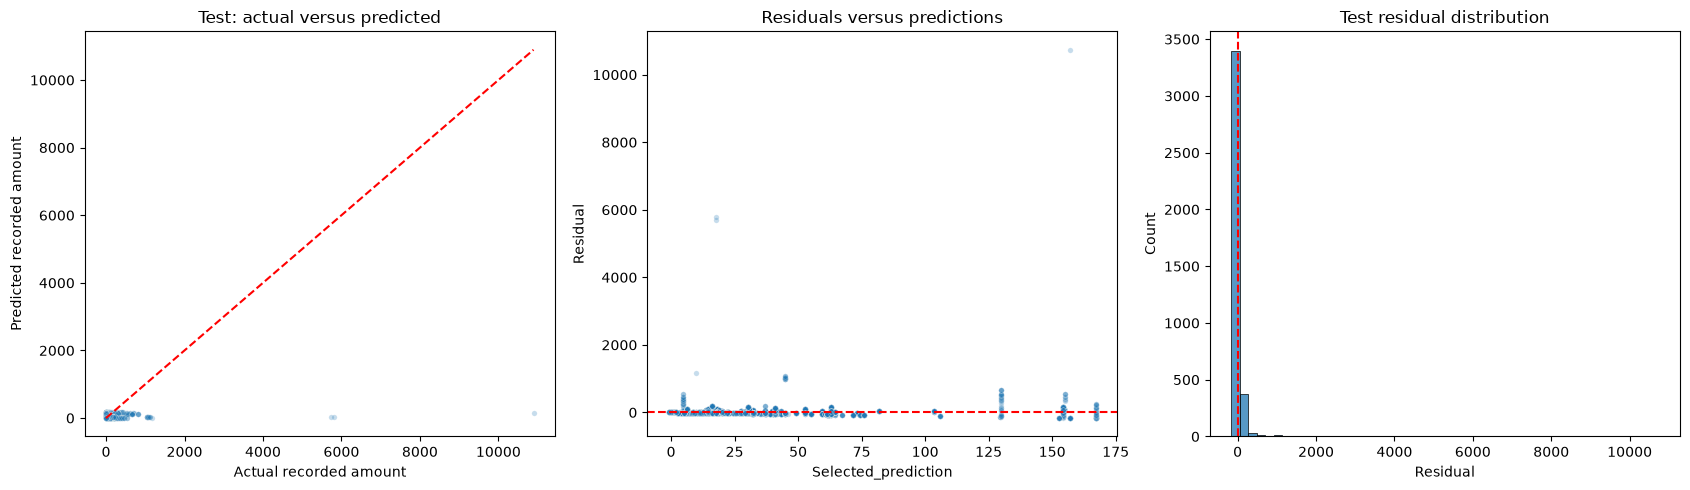

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

figures = project / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Actual versus predicted
sns.scatterplot(
    data=test_predictions,
    x="Actual",
    y="Selected_prediction",
    alpha=0.25,
    s=15,
    ax=axes[0],
)

lower = min(
    0,
    test_predictions["Selected_prediction"].min(),
)
upper = max(
    test_predictions["Actual"].max(),
    test_predictions["Selected_prediction"].max(),
)

axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
)
axes[0].set_title("Test: actual versus predicted")
axes[0].set_xlabel("Actual recorded amount")
axes[0].set_ylabel("Predicted recorded amount")

# Residuals versus predictions
sns.scatterplot(
    data=test_predictions,
    x="Selected_prediction",
    y="Residual",
    alpha=0.25,
    s=15,
    ax=axes[1],
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals versus predictions")

# Residual distribution
sns.histplot(
    data=test_predictions,
    x="Residual",
    bins=50,
    ax=axes[2],
)
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_title("Test residual distribution")

fig.tight_layout()
fig.savefig(
    figures / "final_test_prediction_errors.png",
    dpi=160,
)
plt.show()